In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
archivo = 'https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/DA0101EN/automobileEDA.csv'
df = pd.read_csv(archivo)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    object 
 3   aspiration         201 non-null    object 
 4   num-of-doors       201 non-null    object 
 5   body-style         201 non-null    object 
 6   drive-wheels       201 non-null    object 
 7   engine-location    201 non-null    object 
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    object 
 14  num-of-cylinders   201 non-null    object 
 15  engine-size        201 non-null    int64  
 16  fuel-system        201 non

#  Estadística Descriptiva
Permite explorar los datos con el propósito de hallar las características principales, mediante la implementación de gráficas y el cálculo de algunas variable estadísticas.

## Estimaciones de ubicación

* Media
* Media ponderada: suma de todos los valores multiplicada por un peso, dividida entre la suma de los pesos.
* Mediana (percentil 50): Valor tal que la mitad de los datos se encuentra por encima y por debajo.
* Mediana ponderada: Valor tal que la mitad de la suma de los pesos se encuentra por encima y por debajo de los datos ordenados.
* Media recortada (media truncada): Promedio de todos los valores después de descartar un número fijo de valores extremos.
* Percentil (cuantil): Valor tal que el $p$ por ciento de los datos se encuentra por debajo. Sinónimo
* Valor atípico.

In [ ]:
# Para dar una descripción estadística de variables numéricas:
df.describe()

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,diesel,gas
count,201.000000,201.00000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,197.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000
mean,0.840796,122.00000,98.797015,0.837102,0.915126,53.766667,2555.666667,126.875622,3.330692,3.256904,10.164279,103.405534,5117.665368,25.179104,30.686567,13207.129353,9.944145,0.099502,0.900498
std,1.254802,31.99625,6.066366,0.059213,0.029187,2.447822,517.296727,41.546834,0.268072,0.319256,4.004965,37.365700,478.113805,6.423220,6.815150,7947.066342,2.534599,0.300083,0.300083
min,-2.000000,65.00000,86.600000,0.678039,0.837500,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000,4.795918,0.000000,0.000000
25%,0.000000,101.00000,94.500000,0.801538,0.890278,52.000000,2169.000000,98.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000,7.833333,0.000000,1.000000
50%,1.000000,122.00000,97.000000,0.832292,0.909722,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5125.369458,24.000000,30.000000,10295.000000,9.791667,0.000000,1.000000
75%,2.000000,137.00000,102.400000,0.881788,0.925000,55.500000,2926.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000,12.368421,0.000000,1.000000
max,3.000000,256.00000,120.900000,1.000000,1.000000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,262.000000,6600.000000,49.000000,54.000000,45400.000000,18.076923,1.000000,1.000000


<Axes: xlabel='drive-wheels', ylabel='price'>

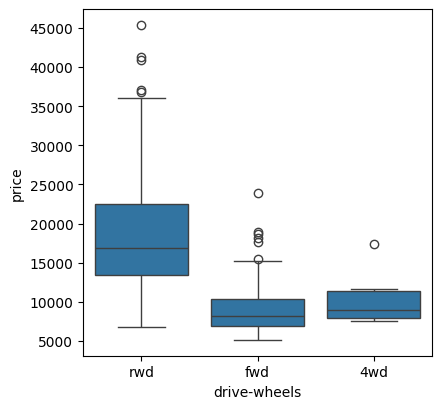

In [ ]:
# Diagramas de cajas permiten comparar facilmente diferentes grupos.

plt.figure(figsize=(4.5, 4.5))
sns.boxplot(x="drive-wheels",y="price", data=df)

En este ejemplo, podemos ver diferentes categorías y sus distribuciones respecto al precio:

Vemos que el precio de los carros rwd son distintos a los de otras categorias. El precio de los carros fwd y 4×4 son casi indistinguibles.


In [ ]:
df.groupby(["drive-wheels"])['price'].describe()

,count,mean,std,min,25%,50%,75%,max
drive-wheels,,,,,,,,
4wd,8.0,10241.000000,3288.211064,7603.0,7984.25,9005.5,11367.75,17450.0
fwd,118.0,9244.779661,3345.898257,5118.0,6950.75,8192.0,10332.50,23875.0
rwd,75.0,19757.613333,9082.575728,6785.0,13455.00,16900.0,22547.50,45400.0


In [ ]:
# Para contabilizar variables categóricas o numméricas:
df["drive-wheels"].value_counts()

,count
drive-wheels,
fwd,118
rwd,75
4wd,8


In [ ]:
#Media
df.mean(numeric_only=True)

,0
symboling,0.840796
normalized-losses,122.000000
wheel-base,98.797015
length,0.837102
width,0.915126
height,53.766667
curb-weight,2555.666667
engine-size,126.875622
bore,3.330692
stroke,3.256904


In [ ]:
# Definir los percentiles que queremos calcular
percentiles = [25, 50, 75]  # 25%, 50%, 75%

# Calcular percentiles
percentile_values = np.percentile(df['price'], percentiles)
percentile_values

array([ 7775., 10295., 16500.])

In [ ]:
# Media ponderada
stats.trim_mean(df['price'], proportiontocut=0.1) # borra el 10% en cada extremo

np.float64(11676.937888198758)

In [ ]:
# Mediana

In [ ]:
percentile_df = pd.DataFrame({'Percentil': [f'{int(p)}%' for p in percentiles],
                              'Valor': percentile_values})
print("Percentiles Calculados:")
percentile_df

Percentiles Calculados:


,Percentil,Valor
0,25%,7775.0
1,50%,10295.0
2,75%,16500.0


### Detección de Puntos Atípicos con Percentiles

Una forma común de identificarlos es mediante los **percentiles** y el **rango intercuartílico (IQR, Interquartile Range)**.

---
Método de Detección usando IQR y Percentiles

> Agregar bloque entrecomillado


1. **Calcular el Percentil 25 (Q1)**: El 25% de los datos están por debajo de este valor.  
2. **Calcular el Percentil 75 (Q3)**: El 75% de los datos están por debajo de este valor.  
3. **Calcular el Rango Intercuartílico (IQR)**:  
   $$
   IQR = Q3 - Q1
   $$
4. **Definir los límites para detectar atípicos**:  
   - **Límite inferior**:  
     $$
     Q1 - 1.5 \times IQR
     $$
   - **Límite superior**:  
     $$
     Q3 + 1.5 \times IQR
     $$
5. **Los valores fuera de estos límites se consideran atípicos**.


In [ ]:
Q1 = float(percentile_df.iloc[0, 1])  # type: ignore # Percentil 25
Q3 = float(percentile_df.iloc[2, 1])  # type: ignore # Percentil 75
IQR = Q3 - Q1 # Rango intercuartílico


# Límites para detectar valores atípicos
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Puntos atípicos
outliers = [x for x in df['price'] if x < lower_bound or x > upper_bound]

print(f"Q1 (P25): {Q1}")
print(f"Q3 (P75): {Q3}")
print(f"IQR: {IQR}")
print(f"Límite inferior: {lower_bound}")
print(f"Límite superior: {upper_bound}")
print(f"Puntos atípicos detectados: {outliers}")

Q1 (P25): 7775.0
Q3 (P75): 16500.0
IQR: 8725.0
Límite inferior: -5312.5
Límite superior: 29587.5
Puntos atípicos detectados: [30760.0, 41315.0, 36880.0, 32250.0, 35550.0, 36000.0, 31600.0, 34184.0, 35056.0, 40960.0, 45400.0, 32528.0, 34028.0, 37028.0]


In [ ]:
#Datos atipicos usando la media, desviación estándar y varianza.
anomalias=[]
def buscar_atipicos(dataframe):
  df_std=dataframe.std()
  df_mean=dataframe.mean()
  corteAnomalo=df_std*2 # Varianza
  limite_menor=df_mean-corteAnomalo
  limite_mayor=df_mean+corteAnomalo
  print(limite_menor.iloc[0])
  print(limite_mayor.iloc[0])

  #generacion de las anomalias
  for index, row in dataframe.iterrows():
    outlier=row # obtener columna    fila: columna1|columna2|columna3
    if (outlier.iloc[0]>limite_mayor.iloc[0]) or (outlier.iloc[0]<limite_menor.iloc[0]):
      anomalias.append(index)
  return anomalias

In [ ]:
buscar_atipicos(df[["price"]])

-2687.0033306447112
29101.262037112374


[14, 15, 16, 44, 45, 46, 67, 68, 69, 70, 71, 123, 124, 125]

## Estimadores de variabilidad

* Desviaciones (Errores, residuos): Diferencia entre los valores observados y la estimación de la ubicación.
* Varianza (Error cuadrático medio)
* Desviación estándar
* Desviación absoluta media (MAD, Norma l1, norma de Manhattan): Media de los valores absolutos de las desviaciones con respecto a la media.
* Desviación absoluta mediana con respecto a la mediana
* Mediana de los valores absolutos de las desviaciones con respecto a la mediana.
* Rango: Diferencia entre el valor máximo y el mínimo de un conjunto de datos.
* Estadísticas de orden: Métricas basadas en los valores de los datos ordenados de menor a mayor.



In [ ]:
# desviación estándar
df.std(numeric_only=True)

,0
symboling,1.254802
normalized-losses,31.996250
wheel-base,6.066366
length,0.059213
width,0.029187
height,2.447822
curb-weight,517.296727
engine-size,41.546834
bore,0.268072
stroke,0.319256


In [ ]:
df.mode()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,0.0,122.0,toyota,std,four,sedan,fwd,front,93.7,0.755887,...,9.0,68.0,4800.0,31.0,25.0,5572.0,7.580645,Low,0.0,1.0
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,5500.0,NaN,NaN,6229.0,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,6692.0,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,7295.0,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,7609.0,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,7775.0,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,7898.0,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,7957.0,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,8495.0,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,8845.0,NaN,NaN,NaN,NaN


# Distribucción normal
Se utiliza para modelar datos continuos que pueden tomar cualquier valor dentro de un rango dado, como la altura, el peso, la temperatura, etc.

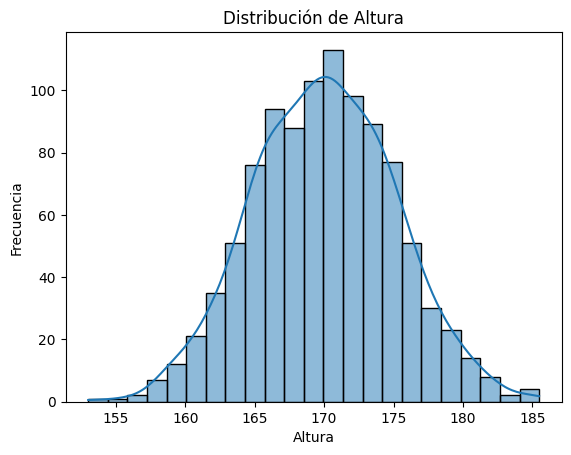

In [ ]:
# Generar datos de altura con distribución normal (media=170, desviación estándar=5)
altura = np.random.normal(170, 5, 1000)
sns.histplot(altura, kde=True)
plt.title('Distribución de Altura')
plt.xlabel('Altura')
plt.ylabel('Frecuencia')
plt.show()

In [ ]:
# Prueba de normalidad
from scipy import stats

# Datos
data_a = [12, 15, 14, 10, 13, 15, 14, 10, 11, 13]
data_b = [14, 18, 17, 12, 16, 17, 16, 12, 13, 16]

In [ ]:
# Prueba de normalidad
# Prueba de Shapiro-Wilk para el grupo A

shapiro_a = stats.shapiro(data_a)
print("Grupo A - Estadístico W:", shapiro_a[0], "Valor p:", shapiro_a[1])

# Prueba de Shapiro-Wilk para el grupo B
shapiro_b = stats.shapiro(data_b)
print("Grupo B - Estadístico W:", shapiro_b[0], "Valor p:", shapiro_b[1])

# alpha < p se acepta la hipótesis nula: Datos de se ditribuyen normal

Grupo A - Estadístico W: 0.9091017619452337 Valor p: 0.27487790949289714
Grupo B - Estadístico W: 0.8931826000696104 Valor p: 0.18411117689917805


# Machine Learning

Dada una respuesta cuantitativa $Y$ y $p$ predictores diferentes, $X_1, X_2,\ldots, X_p$. Si existe alguna relación entre $Y$ y $X = (X_1, X_2,\ldots, X_p)$, puede expresarse de forma $$Y=f(X)+\epsilon$$

donde $f$ es una función  desconocida, $\epsilon$ es un término de error aleatorio, que es independiente de $X$ y tiene media cero.


# Regresiones lineales

$$y=\beta_0+\beta_1x_1+\beta_2x_2+\cdots+\beta_nx_n$$

In [ ]:
from sklearn.linear_model import LinearRegression

# Datos de entreada con tres caraterísticas
X = np.array([[1, 1, 4], [1, 2, 3], [2, 2, 5], [2, 3, 6]])
y = np.dot(X, np.array([4, 2, -1]))

rl = LinearRegression().fit(X, y)


print("Coefiencetes: {}".format(rl.coef_))
print("Intercepto: {}".format(rl.intercept_))
print("Coeficiente r^2: {}".format(rl.score(X, y)))

Coefiencetes: [ 4.  2. -1.]
Intercepto: -8.881784197001252e-16
Coeficiente r^2: 1.0


In [ ]:
rl.predict(np.array([[3, 5, 6]]))

array([16.])

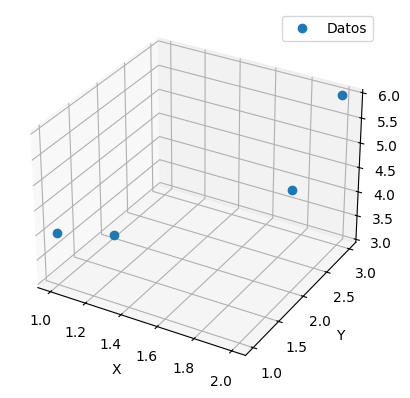

In [ ]:
## Modelo es $y=-8.88+4x_1+2x_2-1x_3$

ax = plt.figure().add_subplot(projection='3d')

# Prepare arrays x, y, z
z = X[:,2]
x = X[:,0]
y = X[:,1]

ax.plot(x, y, z, 'o',label='Datos')

ax.legend()
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.show()

## Correlación


La correlación es una medida de la relación entre variables que se mide en una escala de -1 a 1. Cuanto más cercano sea el valor de correlación a -1 o 1, más fuerte será la relación, y mientras más cerca de 0, más débil será la relación.

Algunos tipos de pruebas para medir la correlación: Pearson, Spearman y Kendall.


* Pearson: las variables deben estar normalmente distribuidas. Otras suposiciones incluyen linealidad y homogeneidad en la varianza.

* Kendall: Debe haber una relación monotónica entre las variables.

* Spearman: Debe haber relación monotónica entre las variables.


<Axes: xlabel='engine-size', ylabel='price'>

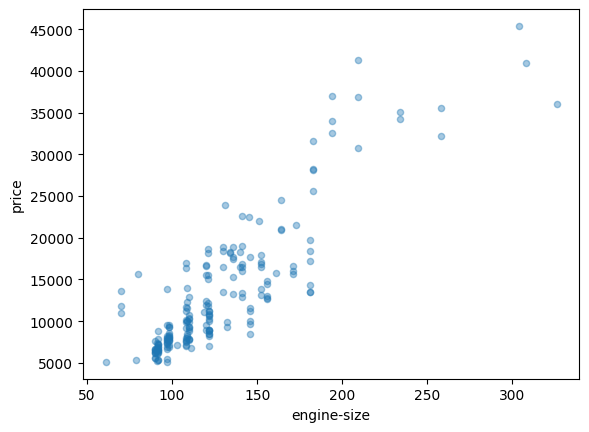

In [ ]:
# test de lienalidad
df.plot(kind="scatter", y = "price", x = "engine-size", alpha = 0.4)

sí hay una relación lineal entre las variables.

In [ ]:
from scipy.stats import skewtest, levene


# Test de hipótesis nula.  H0: la muestra se distribuye normal.
print(skewtest(df["price"]))
print(skewtest(df["engine-size"]))

# Test de hipótesis nula. H0: Las muestras provienen de una población con varianzas iguales
print(levene(df["price"],df["engine-size"]))

# alpha < p se acepta la hipótesis nula

SkewtestResult(statistic=np.float64(7.639137730516152), pvalue=np.float64(2.186812829722033e-14))
SkewtestResult(statistic=np.float64(8.058856418726215), pvalue=np.float64(7.701148913242647e-16))
LeveneResult(statistic=np.float64(140.81734743196424), pvalue=np.float64(4.916938115048979e-28))


 Los tests de uniformidad de la distribución y homogeneidad arrojan resultados negativos.

 Por lo tanto, la prueba de correlación apropiada para usar sería una prueba no paramétrica como la correlación de Spearman o de Kendall.

In [ ]:
corr_p = df[['price','engine-size']].corr()
corr_k = df[['price','engine-size']].corr(method = "kendall")
corr_s = df[['price','engine-size']].corr(method = "spearman")

corr_s

,price,engine-size
price,1.000000,0.828417
engine-size,0.828417,1.000000


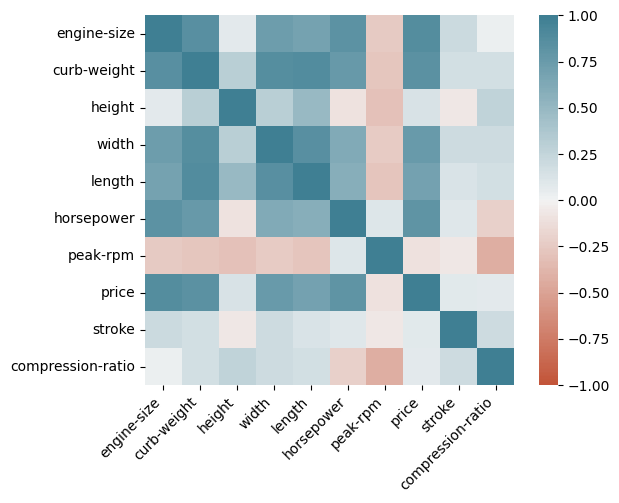

In [ ]:
df_new = df[['engine-size','curb-weight','height','width','length','horsepower','peak-rpm','price','stroke','compression-ratio']]
corr_new = df_new.corr()

ax = sns.heatmap(
    corr_new,
    vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(20, 220, n=200), # type: ignore # Ignora la advertencia de tipo de Pylance
    square=True
)
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    horizontalalignment='right'
);

In [ ]:
df1=pd.read_csv('Advertising.csv')
df1.head()

FileNotFoundError: [Errno 2] No such file or directory: 'Advertising.csv'

In [ ]:
corr_p = df1[['sales','TV']].corr()
np.sqrt(df1['TV'].var())